# Taller 2 — Notebook 04: Entrenamiento de los modelos

**MINE-4101 · Predicción de churn para FinAlpes** · **Integrantes:** Daniel Triviño · Nicolás Bedoya

Entregable 2. Decisiones:

- Partición 80/20 estratificada; validación cruzada de 5 particiones en entrenamiento.
- Modelos: regresión logística, SVM y XGBoost.
- `gender` y `country` fuera del modelo (categoría protegida y variable que no existe en el banco colombiano); se
  guardan para auditar. `age` se conserva.
- Pipeline: imputación con la mediana, `products_number` como categoría y escalado.
- Desbalance: comparación de ninguna, pesos de clase y SMOTE.
- Métrica de selección: PR-AUC.

> Ejecutar después de `02_limpieza`.

In [1]:
import json
import os
import time

import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (brier_score_loss, f1_score, make_scorer, precision_recall_curve, precision_score,
                             recall_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')

RUTA_LIMPIO = '../data/processed/churn_limpio.parquet'
RUTA_PROCESADOS = '../data/processed'
RUTA_FIGS = '../figs'
os.makedirs(RUTA_FIGS, exist_ok=True)

SEMILLA = 42   # misma semilla en todo el notebook, para que los resultados se puedan repetir


## 1. Variables del modelo

In [2]:
df = pd.read_parquet(RUTA_LIMPIO)

OBJETIVO = 'churn'
NUMERICAS = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']
CATEGORICAS = ['products_number', 'credit_card', 'active_member']
VARIABLES_MODELO = NUMERICAS + CATEGORICAS
VARIABLES_AUDITORIA = ['gender', 'country', 'age']   # para revisar después si el modelo trata distinto a cada grupo

# credit_score y age vienen como enteros que admiten faltantes (Int64); scikit-learn trabaja con float y NaN
X = df[VARIABLES_MODELO].astype(float)
y = df[OBJETIVO]
print(f'Filas: {len(df):,}  |  variables del modelo: {len(VARIABLES_MODELO)}  |  churn: {y.mean() * 100:.2f}%')
print('Faltantes por variable del modelo:', X.isna().sum()[X.isna().sum() > 0].to_dict())


Filas: 9,985  |  variables del modelo: 8  |  churn: 20.38%
Faltantes por variable del modelo: {'credit_score': 250, 'age': 300, 'balance': 200, 'estimated_salary': 350}


## 2. Partición en entrenamiento y prueba

In [3]:
idx_train, idx_test = train_test_split(df.index, test_size=0.2, stratify=y, random_state=SEMILLA)
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

display(pd.DataFrame({'filas': [len(idx_train), len(idx_test)],
                      'churn_%': [y_train.mean() * 100, y_test.mean() * 100]},
                     index=['entrenamiento', 'prueba']))

particion = pd.Series('entrenamiento', index=df.index)
particion.loc[idx_test] = 'prueba'
df.assign(particion=particion).to_parquet(f'{RUTA_PROCESADOS}/churn_particion.parquet', index=False)
print(f'Partición guardada en {RUTA_PROCESADOS}/churn_particion.parquet')


,filas,churn_%
entrenamiento,7988,20.381
prueba,1997,20.381


Partición guardada en ../data/processed/churn_particion.parquet


## 3. Validación cruzada

Las mismas 5 particiones para todas las comparaciones.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)


## 4. Pipeline

Imputar (mediana) → SMOTENC (solo en esa estrategia y solo al entrenar) → escalar y codificar → modelo.

In [5]:
N_NUM = len(NUMERICAS)
IDX_PRODUCTOS = N_NUM                     # posición de products_number después de imputar
IDX_BINARIAS = [N_NUM + 1, N_NUM + 2]     # posiciones de credit_card y active_member

def construir_pipeline(modelo, smote=False):
    '''imputar (mediana) -> [SMOTENC] -> escalar numéricas y codificar products_number -> modelo.'''
    imputar = ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), NUMERICAS),
        ('categoricas', 'passthrough', CATEGORICAS),
    ])
    preparar = ColumnTransformer([
        ('escalar', StandardScaler(), list(range(N_NUM))),
        ('productos', OneHotEncoder(handle_unknown='ignore'), [IDX_PRODUCTOS]),
        ('binarias', 'passthrough', IDX_BINARIAS),
    ])
    pasos = [('imputar', imputar)]
    if smote:
        pasos.append(('smote', SMOTENC(categorical_features=[IDX_PRODUCTOS] + IDX_BINARIAS, random_state=SEMILLA)))
    pasos += [('preparar', preparar), ('modelo', modelo)]
    return Pipeline(pasos)


## 5. Comparación de estrategias de desbalance

Con hiperparámetros por defecto. Métricas: PR-AUC (selección), ROC-AUC, precisión, recall, F1 y calidad de las
probabilidades (probabilidad media predicha frente a la tasa real, y Brier score). La SVM no entrega probabilidades,
así que no tiene estas dos últimas.

Precisión, recall y F1 van con el umbral por defecto (`_def`) y con el que maximiza el F1 (`_f1`): pesos y SMOTE
inflan las probabilidades, y con el umbral por defecto parecen mejores solo por eso.

In [6]:
peso_positivo = (y_train == 0).sum() / (y_train == 1).sum()   # cuántos se quedan por cada uno que abandona

def modelo_base(nombre, pesos=False):
    '''Modelo con hiperparámetros por defecto; con `pesos=True`, ponderando más la clase que abandona.'''
    if nombre == 'Regresión logística':
        return LogisticRegression(max_iter=2000, class_weight='balanced' if pesos else None)
    if nombre == 'SVM':
        return SVC(kernel='rbf', class_weight='balanced' if pesos else None)
    if nombre == 'XGBoost':
        return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, eval_metric='logloss',
                             scale_pos_weight=peso_positivo if pesos else 1, random_state=SEMILLA, n_jobs=1)
    raise ValueError(nombre)

MODELOS = ['Regresión logística', 'SVM', 'XGBoost']
ESTRATEGIAS = ['ninguna', 'pesos de clase', 'SMOTE']
print(f'Proporción entre clases en entrenamiento (se quedan por cada uno que abandona): {peso_positivo:.2f}')


Proporción entre clases en entrenamiento (se quedan por cada uno que abandona): 3.91


In [7]:
def metricas_umbral_f1(y_real, puntaje):
    '''Umbral que maximiza el F1 sobre puntajes de validación cruzada, con la precisión y el recall en ese umbral.'''
    precision, recall, umbrales = precision_recall_curve(y_real, puntaje)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    i = int(np.argmax(f1[:-1]))          # el último punto de la curva no tiene umbral asociado
    return {'umbral_f1': umbrales[i], 'precision_f1': precision[i], 'recall_f1': recall[i], 'f1_max': f1[i]}

# Si en alguna partición un modelo no marca a nadie como 'se va', la precisión es 0/0: la contamos como 0
METRICAS_CV = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc',
               'precision': make_scorer(precision_score, zero_division=0),
               'recall': make_scorer(recall_score, zero_division=0),
               'f1': make_scorer(f1_score, zero_division=0)}

filas = []
for nombre in MODELOS:
    for estrategia in ESTRATEGIAS:
        pipe = construir_pipeline(modelo_base(nombre, pesos=(estrategia == 'pesos de clase')),
                                  smote=(estrategia == 'SMOTE'))
        inicio = time.time()
        res = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=-1, scoring=METRICAS_CV)
        fila = {'modelo': nombre, 'estrategia': estrategia,
                'pr_auc': res['test_pr_auc'].mean(), 'pr_auc_desv': res['test_pr_auc'].std(),
                'roc_auc': res['test_roc_auc'].mean(),
                'precision_def': res['test_precision'].mean(), 'recall_def': res['test_recall'].mean(),
                'f1_def': res['test_f1'].mean()}
        metodo = 'decision_function' if nombre == 'SVM' else 'predict_proba'
        puntaje = cross_val_predict(pipe, X_train, y_train, cv=cv, method=metodo, n_jobs=-1)
        if metodo == 'predict_proba':
            puntaje = puntaje[:, 1]
            fila['prob_media_%'] = puntaje.mean() * 100
            fila['brier'] = brier_score_loss(y_train, puntaje)
        fila.update(metricas_umbral_f1(y_train, puntaje))
        fila['segundos'] = round(time.time() - inicio, 1)
        filas.append(fila)

comparacion = pd.DataFrame(filas)
print(f'Tasa real de churn en entrenamiento: {y_train.mean() * 100:.1f}%')
print('Métricas que no dependen del umbral:')
display(comparacion[['modelo', 'estrategia', 'pr_auc', 'pr_auc_desv', 'roc_auc', 'prob_media_%', 'brier']])
print('Métricas que dependen del umbral: con el umbral por defecto (_def) y con el que maximiza el F1 (_f1):')
display(comparacion[['modelo', 'estrategia', 'precision_def', 'recall_def', 'f1_def',
                     'umbral_f1', 'precision_f1', 'recall_f1', 'f1_max']])


Tasa real de churn en entrenamiento: 20.4%
Métricas que no dependen del umbral:


,modelo,estrategia,pr_auc,pr_auc_desv,roc_auc,prob_media_%,brier
0,Regresión logística,ninguna,0.592,0.036,0.814,20.376,0.121
1,Regresión logística,pesos de clase,0.585,0.036,0.815,41.183,0.173
2,Regresión logística,SMOTE,0.572,0.040,0.808,37.585,0.170
3,SVM,ninguna,0.638,0.024,0.799,NaN,NaN
4,SVM,pesos de clase,0.620,0.023,0.826,NaN,NaN
5,SVM,SMOTE,0.570,0.026,0.807,NaN,NaN
6,XGBoost,ninguna,0.669,0.016,0.841,20.246,0.109
7,XGBoost,pesos de clase,0.666,0.020,0.837,36.715,0.147
8,XGBoost,SMOTE,0.659,0.021,0.836,26.402,0.118


Métricas que dependen del umbral: con el umbral por defecto (_def) y con el que maximiza el F1 (_f1):


,modelo,estrategia,precision_def,recall_def,f1_def,umbral_f1,precision_f1,recall_f1,f1_max
0,Regresión logística,ninguna,0.721,0.317,0.440,0.316,0.533,0.571,0.551
1,Regresión logística,pesos de clase,0.417,0.724,0.529,0.623,0.519,0.590,0.552
2,Regresión logística,SMOTE,0.422,0.703,0.527,0.706,0.561,0.526,0.543
3,SVM,ninguna,0.817,0.356,0.495,-0.727,0.645,0.533,0.584
4,SVM,pesos de clase,0.482,0.702,0.572,0.507,0.579,0.579,0.579
5,SVM,SMOTE,0.448,0.693,0.544,0.308,0.503,0.631,0.560
6,XGBoost,ninguna,0.755,0.434,0.551,0.314,0.596,0.585,0.591
7,XGBoost,pesos de clase,0.490,0.690,0.573,0.632,0.603,0.579,0.590
8,XGBoost,SMOTE,0.613,0.558,0.584,0.478,0.603,0.580,0.592


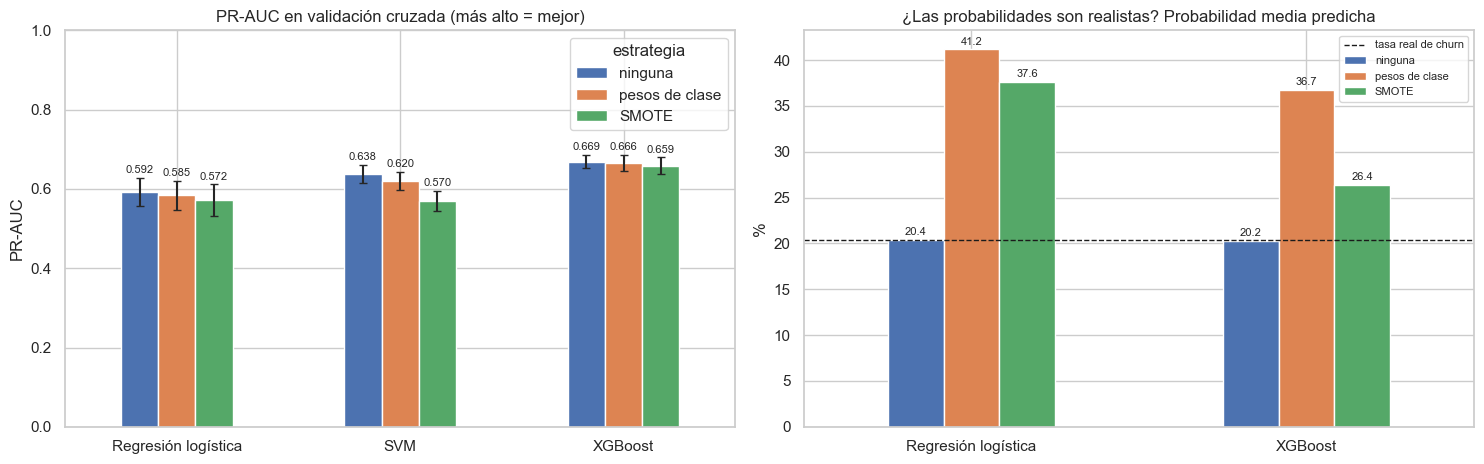

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

pr = comparacion.pivot(index='modelo', columns='estrategia', values='pr_auc')[ESTRATEGIAS]
desv = comparacion.pivot(index='modelo', columns='estrategia', values='pr_auc_desv')[ESTRATEGIAS]
pr.plot(kind='bar', yerr=desv, capsize=3, rot=0, ax=axes[0])
axes[0].set_title('PR-AUC en validación cruzada (más alto = mejor)')
axes[0].set_ylabel('PR-AUC'); axes[0].set_xlabel(''); axes[0].set_ylim(0, 1)
for barras in axes[0].containers:
    if hasattr(barras, 'patches'):
        axes[0].bar_label(barras, fmt='%.3f', fontsize=8, padding=2)

prob = comparacion.dropna(subset=['prob_media_%']).pivot(index='modelo', columns='estrategia',
                                                          values='prob_media_%')[ESTRATEGIAS]
prob.plot(kind='bar', rot=0, ax=axes[1])
axes[1].axhline(y_train.mean() * 100, color='k', ls='--', lw=1, label='tasa real de churn')
axes[1].set_title('¿Las probabilidades son realistas? Probabilidad media predicha')
axes[1].set_ylabel('%'); axes[1].set_xlabel(''); axes[1].legend(fontsize=8)
for barras in axes[1].containers:
    axes[1].bar_label(barras, fmt='%.1f', fontsize=8, padding=2)

plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/04_comparacion_desbalance.png', bbox_inches='tight'); plt.show()


**Decisión:** el modelo final usa la estrategia **ninguna** (sin tocar los datos). Las otras dos quedan como
documentación de la comparación.

**Qué vemos:** _(por completar)_

## 6. Búsqueda de hiperparámetros

Grilla por modelo, con la misma validación cruzada; se elige la combinación con mayor PR-AUC.

In [9]:
GRILLAS = {
    'Regresión logística': {'modelo__C': [0.01, 0.1, 1, 10, 100]},
    'SVM': {'modelo__C': [0.1, 1, 10], 'modelo__gamma': ['scale', 0.01, 0.1]},
    'XGBoost': {'modelo__n_estimators': [200, 400], 'modelo__max_depth': [3, 5],
                'modelo__learning_rate': [0.03, 0.1], 'modelo__subsample': [0.8, 1.0],
                'modelo__colsample_bytree': [0.8, 1.0]},
}

busquedas = {}
for nombre in MODELOS:
    inicio = time.time()
    busqueda = GridSearchCV(construir_pipeline(modelo_base(nombre)), GRILLAS[nombre], scoring=METRICAS_CV,
                            refit='pr_auc', cv=cv, n_jobs=-1)
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    print(f'{nombre}: {len(busqueda.cv_results_["params"])} combinaciones en {time.time() - inicio:.0f} s  |  '
          f'mejor PR-AUC {busqueda.best_score_:.3f} con {busqueda.best_params_}')


Regresión logística: 5 combinaciones en 0 s  |  mejor PR-AUC 0.594 con {'modelo__C': 100}


SVM: 9 combinaciones en 18 s  |  mejor PR-AUC 0.641 con {'modelo__C': 1, 'modelo__gamma': 0.1}


XGBoost: 32 combinaciones en 7 s  |  mejor PR-AUC 0.675 con {'modelo__colsample_bytree': 0.8, 'modelo__learning_rate': 0.03, 'modelo__max_depth': 3, 'modelo__n_estimators': 400, 'modelo__subsample': 1.0}


Las 5 mejores combinaciones de cada modelo:

In [10]:
for nombre, busqueda in busquedas.items():
    res = pd.DataFrame(busqueda.cv_results_)
    res['hiperparametros'] = res['params'].apply(lambda p: {k.replace('modelo__', ''): v for k, v in p.items()})
    print(f'--- {nombre} ---')
    display(res.sort_values('rank_test_pr_auc')[['rank_test_pr_auc', 'hiperparametros', 'mean_test_pr_auc',
                                                  'std_test_pr_auc', 'mean_test_roc_auc']].head(5))


--- Regresión logística ---


,rank_test_pr_auc,hiperparametros,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc
4,1,{'C': 100},0.594,0.036,0.814
3,2,{'C': 10},0.594,0.036,0.814
2,3,{'C': 1},0.592,0.036,0.814
1,4,{'C': 0.1},0.584,0.038,0.814
0,5,{'C': 0.01},0.520,0.036,0.808


--- SVM ---


,rank_test_pr_auc,hiperparametros,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc
5,1,"{'C': 1, 'gamma': 0.1}",0.641,0.026,0.810
3,2,"{'C': 1, 'gamma': 'scale'}",0.638,0.024,0.799
0,3,"{'C': 0.1, 'gamma': 'scale'}",0.637,0.026,0.817
2,4,"{'C': 0.1, 'gamma': 0.1}",0.634,0.027,0.819
8,5,"{'C': 10, 'gamma': 0.1}",0.633,0.025,0.793


--- XGBoost ---


,rank_test_pr_auc,hiperparametros,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc
3,1,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.675,0.019,0.846
1,2,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.675,0.021,0.846
2,3,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.675,0.020,0.846
0,4,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.674,0.021,0.846
18,5,"{'colsample_bytree': 1.0, 'learning_rate': 0.0...",0.674,0.020,0.845


**Qué vemos:** _(por completar)_

## 7. Selección del modelo

Se elige el de mayor PR-AUC en validación cruzada. El umbral definitivo se fija después, según la ganancia esperada.

In [11]:
filas, puntajes_cv = [], {}
for nombre, busqueda in busquedas.items():
    i, r = busqueda.best_index_, busqueda.cv_results_
    metodo = 'decision_function' if nombre == 'SVM' else 'predict_proba'
    puntaje = cross_val_predict(busqueda.best_estimator_, X_train, y_train, cv=cv, method=metodo, n_jobs=-1)
    puntaje = puntaje[:, 1] if metodo == 'predict_proba' else puntaje
    puntajes_cv[nombre] = puntaje
    fila = {'modelo': nombre, 'pr_auc': r['mean_test_pr_auc'][i], 'pr_auc_desv': r['std_test_pr_auc'][i],
            'roc_auc': r['mean_test_roc_auc'][i], 'precision_def': r['mean_test_precision'][i],
            'recall_def': r['mean_test_recall'][i], 'f1_def': r['mean_test_f1'][i]}
    fila.update(metricas_umbral_f1(y_train, puntaje))
    filas.append(fila)

seleccion = pd.DataFrame(filas).set_index('modelo').sort_values('pr_auc', ascending=False)
MODELO_ELEGIDO = seleccion.index[0]
display(seleccion)
print(f'Modelo elegido (mayor PR-AUC en validación cruzada): {MODELO_ELEGIDO}')


,pr_auc,pr_auc_desv,roc_auc,precision_def,recall_def,f1_def,umbral_f1,precision_f1,recall_f1,f1_max
modelo,,,,,,,,,,
XGBoost,0.675,0.019,0.846,0.769,0.424,0.546,0.332,0.634,0.567,0.599
SVM,0.641,0.026,0.810,0.819,0.350,0.490,-0.732,0.645,0.529,0.582
Regresión logística,0.594,0.036,0.814,0.722,0.318,0.441,0.311,0.528,0.576,0.551


Modelo elegido (mayor PR-AUC en validación cruzada): XGBoost


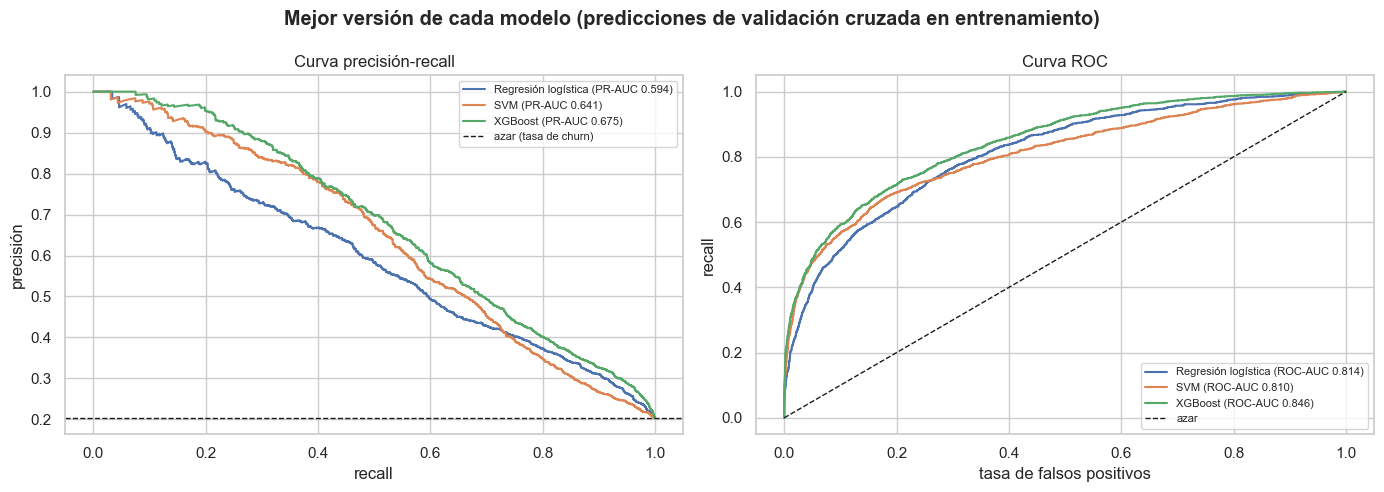

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, puntaje in puntajes_cv.items():
    precision, recall, _ = precision_recall_curve(y_train, puntaje)
    axes[0].plot(recall, precision, label=f'{nombre} (PR-AUC {seleccion.loc[nombre, "pr_auc"]:.3f})')
    fpr, tpr, _ = roc_curve(y_train, puntaje)
    axes[1].plot(fpr, tpr, label=f'{nombre} (ROC-AUC {seleccion.loc[nombre, "roc_auc"]:.3f})')
axes[0].axhline(y_train.mean(), color='k', ls='--', lw=1, label='azar (tasa de churn)')
axes[0].set_title('Curva precisión-recall'); axes[0].set_xlabel('recall'); axes[0].set_ylabel('precisión')
axes[1].plot([0, 1], [0, 1], color='k', ls='--', lw=1, label='azar')
axes[1].set_title('Curva ROC'); axes[1].set_xlabel('tasa de falsos positivos'); axes[1].set_ylabel('recall')
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle('Mejor versión de cada modelo (predicciones de validación cruzada en entrenamiento)', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{RUTA_FIGS}/04_curvas_pr_roc.png', bbox_inches='tight'); plt.show()


**Qué vemos:** _(por completar)_

## 8. Guardar los modelos

Los tres modelos entrenados con todo el entrenamiento (la SVM, calibrada para que dé probabilidades) y
`seleccion.json`.

In [13]:
RUTA_MODELOS = f'{RUTA_PROCESADOS}/modelos'
os.makedirs(RUTA_MODELOS, exist_ok=True)
ARCHIVOS = {'Regresión logística': 'logistica.joblib', 'SVM': 'svm.joblib', 'XGBoost': 'xgboost.joblib'}

for nombre, busqueda in busquedas.items():
    modelo = busqueda.best_estimator_
    if nombre == 'SVM':
        modelo = CalibratedClassifierCV(busqueda.best_estimator_, method='sigmoid', cv=cv).fit(X_train, y_train)
    joblib.dump(modelo, f'{RUTA_MODELOS}/{ARCHIVOS[nombre]}')

seleccion_json = {
    'modelo_elegido': MODELO_ELEGIDO,
    'criterio': 'mayor PR-AUC en validación cruzada de 5 particiones (entrenamiento)',
    'variables_modelo': VARIABLES_MODELO,
    'hiperparametros': {n: {k.replace('modelo__', ''): v for k, v in b.best_params_.items()}
                        for n, b in busquedas.items()},
    'archivos': ARCHIVOS,
}
with open(f'{RUTA_MODELOS}/seleccion.json', 'w', encoding='utf-8') as f:
    json.dump(seleccion_json, f, ensure_ascii=False, indent=2)
print('Modelos guardados en', RUTA_MODELOS, '->', sorted(os.listdir(RUTA_MODELOS)))


Modelos guardados en ../data/processed/modelos -> ['logistica.joblib', 'seleccion.json', 'svm.joblib', 'xgboost.joblib']
